# Aperture calculations

In the previous notebook we saved the shared aperture definitions and the line's
placements and settings as `aperture_model.json`. Here we reload the lattice and the model.

The aperture model gives the available transverse cross-section at any longitudinal position `s`. Once the model is combined with optics and beam parameters, we can ask questions such as:

- What does the aperture cross-section look like here?
- What beam envelope corresponds to a given number of sigmas?
- What is the limiting aperture, expressed as `n1`, at an element or at selected `s` positions?
- What are the horizontal, vertical, and diagonal aperture margins?
- How can the interpolated aperture be converted back into ordinary `LimitPolygon` elements?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xtrack as xt

# Load the lattice + the model
env = xt.load("toy_ring.json")
env.aperture.from_json("aperture_model.json")

ring = env["ring"]

model = ring.aperture
model.build_model()
twiss = ring.twiss()

print(model)

Loading line from dict:   0%|          | 0/84 [00:00<?, ?it/s]

Done loading line from dict.           
Done loading line from dict.           


Building cross-sections:   0%|          | 0/244 [00:00<?, ?it/s]

<LineAperture: 114 pipe positions>


## Cross-sections (profile interpolation)

The lowest-level useful query is the interpolated aperture cross-section. We can sample at arbitrary `s` positions with `get_cross_sections_at_s`, or across an element with `get_cross_sections_at_element`.

For axis intersections without polygons, use `get_extents_at_s` or `get_extents_at_element`.

In [38]:
sample_s = np.arange(10.36, 10.65, 0.05)

# Interpolate at explicit s-positions
sections = model.get_cross_sections_at_s(sample_s, extents=True)
#sections = model.get_cross_sections_at_element("||drift_5", resolution=0.05, extents=True)

# If only extents are of interest, we can use the convenience function:
#extents = model.get_extents_at_s(sample_s)
#mb_extents = model.get_extents_at_element("||drift_5", resolution=0.25)

sections.cols["s cross_section min_x max_x min_y max_y pose"].show(maxwidth="full")
#extents.cols["s min_x max_x min_y max_y pose"].show(maxwidth="full")


index                             s   cross_section         min_x         max_x         min_y         max_y          pose
0                             10.36 <array(128, 2)>    -0.0519548     0.0519548    -0.0519548     0.0519548 <array(4, 4)>
1                             10.41 <array(128, 2)>    -0.0524953      0.052492    -0.0488538     0.0488542 <array(4, 4)>
2                             10.46 <array(128, 2)>    -0.0530309     0.0530235    -0.0457471     0.0457478 <array(4, 4)>
3                             10.51 <array(128, 2)>    -0.0535613     0.0535491    -0.0426346     0.0426354 <array(4, 4)>
4                             10.56 <array(128, 2)>    -0.0540863     0.0540686    -0.0395161     0.0395168 <array(4, 4)>
5                             10.61 <array(128, 2)>     -0.054606     0.0545818    -0.0363915     0.0363918 <array(4, 4)>
Interpolating profiles: 100%

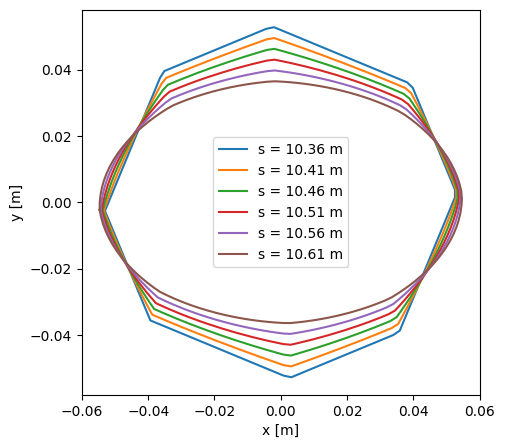

In [39]:
fig, ax = plt.subplots(figsize=(6, 5))
for row in sections.rows:
    polygon = row.cross_section
    ax.plot(polygon[:, 0], polygon[:, 1], label=f"s = {row.s:.2f} m")
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend();

## Beam envelope calculation

To compute the beam envelopes and aperture sigmas the aperture model is combined with:

- local optics and closed-orbit values from Twiss,
- user beam and tolerance parameters in `halo_params`,
- mechanical tolerances attached to the active aperture profile position.

The halo parameters currently configured on the aperture object are:

In [40]:
model.halo_params

{'nemitt_x': 1e-06,
 'nemitt_y': 1e-06,
 'delta_rms': 0.0,
 'tol_co': 0.0,
 'tol_disp': 0.0,
 'tol_disp_ref': 1.0,
 'tol_disp_ref_beta': 1.0,
 'tol_beta_beating': 1.0,
 'halo_x': 1.0,
 'halo_y': 1.0,
 'halo_r': 1.0,
 'halo_primary': 1.0}

This is what each of the values means:

- `nemitt_x` ($\varepsilon_{x,\mathrm{n}}$) and `nemitt_y` ($\varepsilon_{y,\mathrm{n}}$): normalised emittances;
- `delta_rms` ($\delta_\mathrm{rms}$): RMS relative momentum spread;
- `tol_co` ($r_\mathrm{co}$): closed-orbit uncertainty margin;
- `tol_disp` ($f_D$): dispersion-tolerance scaling factor;
- `tol_disp_ref` ($D_\mathrm{ref}$): reference dispersion error;
- `tol_disp_ref_beta` ($\beta_{D,\mathrm{ref}}$): reference beta for dispersion scaling;
- `tol_beta_beating` ($f_\beta$): beta-beating scaling factor;
- `halo_x`, `halo_y`, `halo_r`, `halo_primary`: define the reference beam racetrack shape through
  $h_x = \mathrm{halo\_x}/\mathrm{halo\_primary}$,
  $h_y = \mathrm{halo\_y}/\mathrm{halo\_primary}$, and
  $h_r = \mathrm{halo\_r}/\mathrm{halo\_primary}$.

For a one-betatron-sigma beam, the optical sizes are

$$
\sigma_x = \sqrt{\frac{\varepsilon_{x,\mathrm{n}}}{\gamma_r\beta_r}\,\beta_x}\; f_\beta,
\qquad
\sigma_y = \sqrt{\frac{\varepsilon_{y,\mathrm{n}}}{\gamma_r\beta_r}\,\beta_y}\; f_\beta.
$$

The envelope calculation builds a racetrack-shaped beam from these one-sigma sizes, scales it by the requested number of sigmas, and adds margins from closed orbit, dispersion tolerance, and aperture-profile tolerances. The dispersion tolerance margins used internally scale like

$$
\Delta x_D = f_\beta f_D D_\mathrm{ref}
\sqrt{\frac{\beta_x}{\beta_{D,\mathrm{ref}}}}\,\delta_\mathrm{rms},
\qquad
\Delta y_D = f_\beta f_D D_\mathrm{ref}
\sqrt{\frac{\beta_y}{\beta_{D,\mathrm{ref}}}}\,\delta_\mathrm{rms}.
$$

Finally, the envelope is shifted by the local closed orbit and by the dispersive orbit shift $(D_x\delta_\mathrm{rms}, D_y\delta_\mathrm{rms})$.

In [8]:
model.halo_params.update(
    delta_rms=1.0e-4,
    tol_co=1.0e-3,
    tol_disp=1.0,
)
model.halo_params

{'nemitt_x': 1e-06,
 'nemitt_y': 1e-06,
 'delta_rms': 0.0001,
 'tol_co': 0.001,
 'tol_disp': 1.0,
 'tol_disp_ref': 1.0,
 'tol_disp_ref_beta': 1.0,
 'tol_beta_beating': 1.0,
 'halo_x': 1.0,
 'halo_y': 1.0,
 'halo_r': 1.0,
 'halo_primary': 1.0}

## Calculating the beam envelopes

`plot_transverse(sigmas=...)` draws the aperture cross-sections and the beam envelope at a
chosen number of sigmas. `middle="beam"` keeps the beam reference at the origin;
`middle="aperture"` recentres each cross-section on the aperture.

As described in the plotting helper's docstring, the aperture polygons come from
`get_cross_sections_at_s` and the envelope polygons from `get_envelope_at_s`.
Both have an `_at_element` counterpart when sampling a named element.


Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing beam envelopes: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

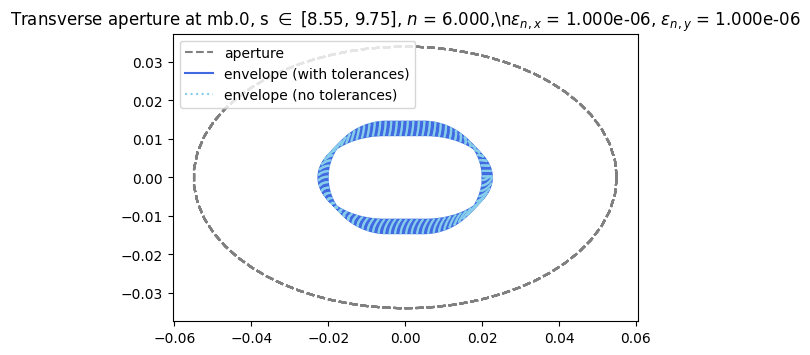

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
model.plot_transverse("mb.0", resolution=0.1, sigmas=6.0, middle="beam", ax=ax);

Immediately after the plot, we can query its aperture and envelope polygons using the
same element, resolution, and sigma level:


In [10]:
mb_sections = model.get_cross_sections_at_element("mb.0", resolution=0.1)
mb_envelopes, mb_twiss = model.get_envelope_at_element(
    "mb.0",
    sigmas=6.0,
    resolution=0.1,
    envelopes_num_points=128,
    include_aper_tols=True,
    polygons=True,
    extents=True,
)
mb_envelopes.show(maxwidth="full")



Interpolating profiles: 100%

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


index                             s   cross_section         min_x         max_x         min_y         max_y
0                           8.54828 <array(128, 2)>    -0.0225364     0.0225364    -0.0110053     0.0110053
1                           8.65769 <array(128, 2)>    -0.0223769     0.0223769     -0.011321      0.011321
2                           8.76709 <array(128, 2)>    -0.0222057     0.0222057    -0.0116372     0.0116372
3                           8.87649 <array(128, 2)>    -0.0220229     0.0220229     -0.011954      0.011954
4                            8.9859 <array(128, 2)>    -0.0218286     0.0218287    -0.0122713     0.0122713
5                            9.0953 <array(128, 2)>     -0.021623      0.021623     -0.012589      0.012589
6                            9.2047 <array(128, 2)>    -0.0214061     0.0214061    -0.0129071     0.0129071
7                            9.3141 <array(128, 2)>    -0.0211781     0.0211781    -0.0132256     0.0132256
8                          

The same helper also accepts explicit `s_positions`, which is useful when the points of interest are not tied to a single element.

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing beam envelopes: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

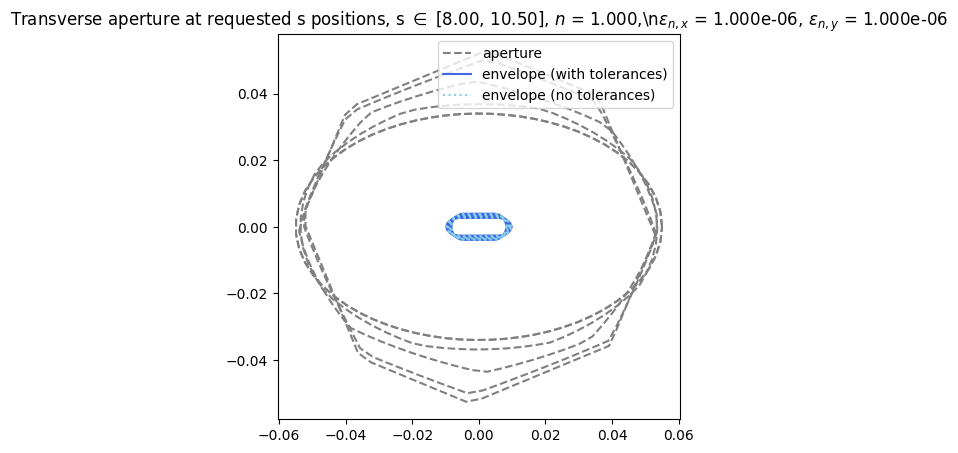

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
model.plot_transverse(s_positions=sample_s, sigmas=1.0, middle="beam", ax=ax);

Here are the data for the explicit positions in the plot above. `cross_section` contains
arrays of `(x, y)` points, while `min_x`, `max_x`, `min_y`, and `max_y` give the extents.
The second returned table contains the sampled Twiss rows.

The helper draws envelopes both with and without aperture mechanical tolerances. We can
obtain both by changing `include_aper_tols`, then plot the polygons ourselves:


In [12]:
envelopes, sliced_twiss = model.get_envelope_at_s(
    sample_s,
    sigmas=1.0,
    envelopes_num_points=128,
    include_aper_tols=True,
    polygons=True,
    extents=True,
)
envelopes_no_tols, _ = model.get_envelope_at_s(
    sample_s, sigmas=1.0, include_aper_tols=False, polygons=True,
)
envelopes.show(maxwidth="full")


Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing beam envelopes: 100%

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


index                             s   cross_section         min_x         max_x         min_y         max_y
0                                 8 <array(128, 2)>   -0.00975987    0.00975989   -0.00266741    0.00266741
1                               8.5 <array(128, 2)>   -0.00951353    0.00951355   -0.00294625    0.00294625
2                                 9 <array(128, 2)>   -0.00917986    0.00917989   -0.00323462    0.00323462
3                               9.5 <array(128, 2)>   -0.00876779    0.00876781   -0.00352211    0.00352211
4                                10 <array(128, 2)>   -0.00833383    0.00833385    -0.0037919     0.0037919
5                              10.5 <array(128, 2)>   -0.00823619    0.00823622   -0.00392796    0.00392796
Computing beam envelopes: 100%

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 100%

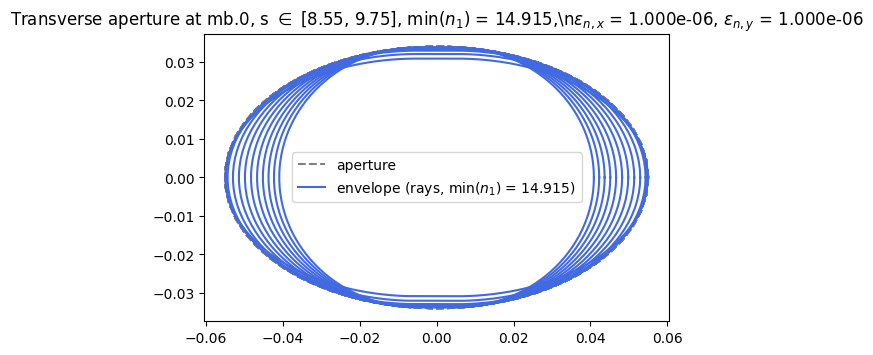

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
model.plot_transverse("mb.0", resolution=0.1, sigmas=None, method="rays", middle="beam", ax=ax);

To retrieve the data behind this plot, call `get_aperture_sigmas_at_element` with the same
element and resolution. Request `output_cross_sections=True` and `output_max_envelopes=True`
to get the aperture polygons in `cross_section` and the limiting-envelope polygons in
`envelope`, alongside the local `n1` values.

Each row contains the envelope at its local limiting `n1`; the plot title reports the
minimum `n1` across the sampled positions.


In [17]:
n1_mb, _ = model.get_aperture_sigmas_at_element(
    "mb.0",
    resolution=0.1,
    method="rays",
    envelopes_num_points=128,
    output_cross_sections=True,
    output_max_envelopes=True,
)
n1_mb.cols["s n1 cross_section envelope"].show(maxwidth="full")


Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


index                             s            n1  cross_section        envelope
0                           8.54828       18.3808 <array(64, 2)> <array(128, 2)>
1                           8.65769       18.5331 <array(64, 2)> <array(128, 2)>
2                           8.76709        18.485 <array(64, 2)> <array(128, 2)>
3                           8.87649       18.1181 <array(64, 2)> <array(128, 2)>
4                            8.9859       17.6933 <array(64, 2)> <array(128, 2)>
5                            9.0953       17.2642 <array(64, 2)> <array(128, 2)>
6                            9.2047       16.8312 <array(64, 2)> <array(128, 2)>
7                            9.3141        16.406 <array(64, 2)> <array(128, 2)>
8                           9.42351       16.0032 <array(64, 2)> <array(128, 2)>
9                           9.53291       15.6213 <array(64, 2)> <array(128, 2)>
10                          9.64231        15.259 <array(64, 2)> <array(128, 2)>
11                         

For explicit `s` positions, use `get_aperture_sigmas_at_s` instead. If polygons are not
needed, leave the `output_...` flags at their default `False` to speed up `rays` and `exact`:


In [18]:
n1_at_s, n1_twiss = model.get_aperture_sigmas_at_s(
    sample_s,
    method="rays",
    num_rays=32,
    output_cross_sections=True,
    output_max_envelopes=True,
)
n1_at_s.show(maxwidth='full')

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


index                             s            n1  cross_section       envelope
0                                 8       16.4911 <array(64, 2)> <array(36, 2)>
1                               8.5       17.7572 <array(64, 2)> <array(36, 2)>
2                                 9       17.6365 <array(64, 2)> <array(36, 2)>
3                               9.5       15.7341 <array(64, 2)> <array(36, 2)>
4                                10       18.8104 <array(64, 2)> <array(36, 2)>
5                              10.5       16.6416 <array(64, 2)> <array(36, 2)>
Computing sigmas: 100%

When a Twiss table has already been sampled, use `get_aperture_sigmas_for_twiss` to avoid recomputing optics.

In [19]:
n1_from_existing_twiss = model.get_aperture_sigmas_for_twiss(
    sliced_twiss=n1_twiss,
    method="rays",
    num_rays=32,
)
n1_from_existing_twiss


Computing sigmas: 100%

Table: 6 rows, 3 cols
index                             s            n1
0                                 8       16.4911
1                               8.5       17.7572
2                                 9       17.6365
3                               9.5       15.7341
4                                10       18.8104
5                              10.5       16.6416

## Horizontal, vertical, and diagonal sigmas

`get_hvd_aperture_sigmas_...` return a table with limiting sigma in three direction families:

- horizontal,
- vertical,
- diagonal at 45 degrees.

This provides more information than `n1`, which does not necessarily help with the directionality.

In [21]:
hvd_table, hvd_twiss = model.get_hvd_aperture_sigmas_at_s(sample_s)
hvd_table

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 16%

Table: 6 rows, 6 cols
index                             s n1_horizontal   n1_vertical   n1_diagonal  cross_section
0                                 8        16.649       35.7192        26.277 <array(64, 2)>
1                               8.5       17.7572       22.3313       20.3038 <array(64, 2)>
2                                 9        19.102       17.8511       17.8619 <array(64, 2)>
3                               9.5       20.2171        15.798       16.9467 <array(64, 2)>
4                                10       20.4601        20.453       19.8662 <array(64, 2)>
5                              10.5       21.1914       17.1789       18.4591 <array(64, 2)>

Computing sigmas: 100%

In [22]:
hvd_mb, _ = model.get_hvd_aperture_sigmas_at_element("mb.0", resolution=0.25)
hvd_mb

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 25%

Table: 4 rows, 6 cols
index                             s n1_horizontal   n1_vertical   n1_diagonal  cross_section
0                           8.54828       18.3808       20.2055       19.2018 <array(64, 2)>
1                           8.94943       19.0088       18.0879       17.9858 <array(64, 2)>
2                           9.35057        19.845       16.3617        17.164 <array(64, 2)>
3                           9.75172       20.9281       14.9296       16.6827 <array(64, 2)>

Computing sigmas: 100%

## Converting sampled aperture back to `LimitPolygon` elements

The function `get_limit_elements_at_s` converts interpolated cross-sections at selected positions into ordinary Xtrack limit elements. This is useful when a calculation needs a conventional element representation rather than the aperture-model object.

In [23]:
limit_elements = model.get_limit_elements_at_s(sample_s[:2])
for s, element in limit_elements.items():
    print(f"s = {s:.3f} m -> {element}")


s = 8.000 m -> LimitPolygon(x_vertices=[ 0.05303722,  0.05106462,  0.04909201,  0.04711941,  0.04514681,
        0.04317421,  0.04120161,  0.039229  ,  0.0372564 ,  0.03475853,
        0.02999625,  0.02523397,  0.02047169,  0.0157094 ,  0.01094712,
        0.00618484,  0.00142256, -0.00333973, -0.00810201, -0.01286429,
       -0.01762658, -0.02238886, -0.02715114, -0.03191342, -0.03667571,
       -0.0402153 , -0.04218791, -0.04416051, -0.04613311, -0.04810571,
       -0.05007831, -0.05205092, -0.05205092, -0.05007831, -0.04810571,
       -0.04613311, -0.04416051, -0.04218791, -0.0402153 , -0.0382427 ,
       -0.0362701 , -0.03237739, -0.02761511, -0.02285283, -0.01809054,
       -0.01332826, -0.00856598, -0.0038037 ,  0.00095859,  0.00572087,
        0.01048315,  0.01524543,  0.02000772,  0.02477   ,  0.02953228,
        0.03429457,  0.03905685,  0.04120161,  0.04317421,  0.04514681,
        0.04711941,  0.04909201,  0.05106462], y_vertices=[-0.00261313,  0.00214916,  0.00691144,  0.0

## Longitudinal extent plots

`plot_extents` gives a longitudinal view: geometric aperture extents in black, limits
reduced by mechanical tolerances as dashed lines, and beam-envelope extents as filled bands.
If `sigmas` is omitted, it uses the minimum `n1` over the requested `s_positions` as the
common beam-envelope size.

The docstring identifies the matching data queries: `get_extents_at_s` for the aperture,
`get_aperture_sigmas_at_s` for the limiting sigma, and `get_envelope_at_s` for the envelope.


Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 100%
Computing beam envelopes: 100%
Interpolating profiles: 100%

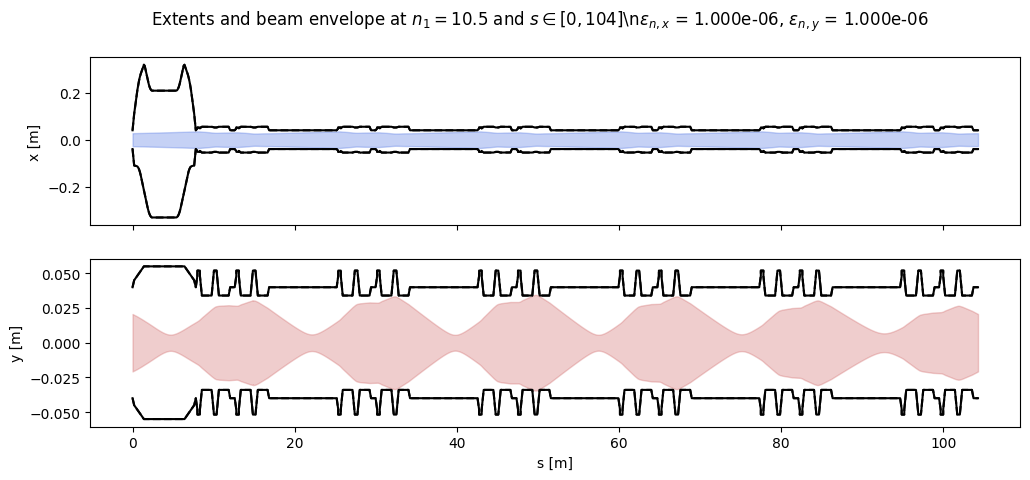

In [24]:
s_sample = model.get_s_around_transitions(resolution=0.1)
model.plot_extents(s_positions=s_sample)
plt.gcf().set_figwidth(12);

These calls obtain the data for the plot above. The geometric limits and tolerances are
returned separately; the dashed horizontal limits are `min_x + tol_x + tol_r` and
`max_x - tol_x - tol_r` (and similarly for `y`).

We leave aperture tolerances out of the filled beam envelope, matching the default
`include_aper_tols=False` in `plot_extents`. For a fixed-sigma plot, pass that sigma directly
to `get_envelope_at_s` and skip the `n1` calculation.


In [31]:
longitudinal_extents = model.get_extents_at_s(s_sample)
longitudinal_n1, longitudinal_twiss = model.get_aperture_sigmas_at_s(s_sample, method="rays")
limiting_sigma = float(np.nanmin(longitudinal_n1.n1))
longitudinal_envelopes, _ = model.get_envelope_at_s(
    s_sample,
    sigmas=limiting_sigma,
    envelopes_num_points=64,
    include_aper_tols=False,
    polygons=False,
    extents=True,
)
longitudinal_extents.cols['s', 'min_x', 'max_x', 'min_y', 'max_y']


Interpolating profiles: 100%

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing sigmas: 100%

Slicing line:   0%|          | 0/140 [00:00<?, ?it/s]


Computing beam envelopes: 15%

Table: 1330 rows, 6 cols
index                             s         min_x         max_x         min_y         max_y
0                                 0    -0.0399503          0.04    -0.0399627     0.0399627
1                             1e-06    -0.0399506     0.0400003    -0.0399627     0.0399627
2                               0.1    -0.0749751     0.0749947     -0.042484     0.0424787
3                          0.199999         -0.11          0.11        -0.045         0.045
4                               0.2         -0.11          0.11        -0.045         0.045
5                          0.200001         -0.11          0.11        -0.045         0.045
6                               0.3     -0.110843      0.136146    -0.0458434     0.0458434
7                               0.4     -0.111687      0.162293    -0.0466869     0.0466869
8                               0.5      -0.11253      0.188439    -0.0475303     0.0475303
9                               0.6     -0.114229      

Computing beam envelopes: 100%